In [1]:
import torch
import matplotlib.pyplot as plt

from ngo.trainingdata.GRF import GRF
from ngo.numericalanalysis.basisfunctions import GaussianRBFBasis, TensorProductBasis

In [2]:
resolution = 101
dx = 1.0 / (resolution - 1)
x = torch.linspace(0,1,resolution, device='cuda', dtype=torch.float64)
y = torch.linspace(0,1,resolution, device='cuda', dtype=torch.float64)
X = (x,y)

In [3]:
torch.cuda.empty_cache()
N_samples = 1
lambdas=(0.5,)
b_min = -1
b_max = 1
b = torch.rand(N_samples)*(b_max - b_min) + b_min
c_min = 0
c_max = 1
c = torch.rand(N_samples)*(c_max - c_min) + c_min
grf = GRF(N_samples=N_samples, lambdas=lambdas, b=b, c=c, device='cuda', dtype=torch.float64, n=None)

/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:59: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.b = torch.tensor(b, device=self.device, dtype=dtype)
/home/joostprins/git/ngo-pde-gk/src/ngo/trainingdata/GRF.py:60: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.c = torch.tensor(c, device=self.device, dtype=dtype)


In [4]:
basis_x = GaussianRBFBasis(lambdas=grf.lambdas[0], mus=grf.mus[0])

In [5]:
Phi = basis_x.forward(x)[0]

In [6]:
Phi.shape

torch.Size([3, 101])

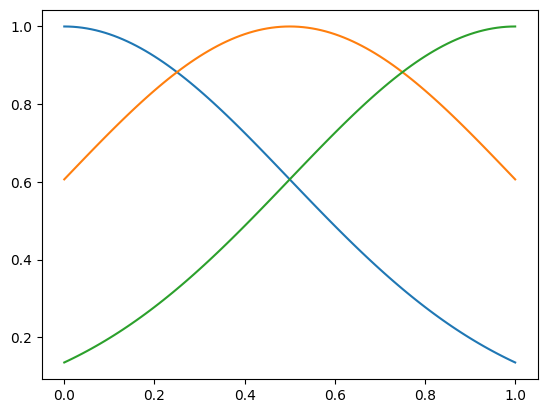

In [7]:
for i in range(Phi.shape[0]):
    plt.plot(x.cpu(), Phi[i,:].cpu())

In [8]:
dPhi = basis_x.grad(x)[0]

In [9]:
dPhi_fd = torch.diff(Phi, dim=1) / dx

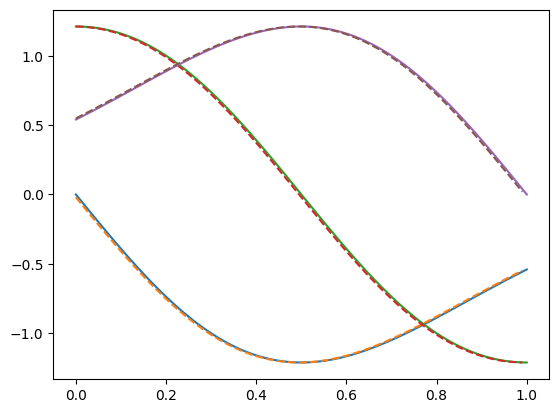

In [10]:
for i in range(Phi.shape[0]):
    plt.plot(x.cpu(), dPhi[i,:].cpu())
    plt.plot(x[:-1].cpu(), dPhi_fd[i,:].cpu(), '--')
    

In [11]:
ddPhi = basis_x.laplacian(x)[0]

In [12]:
ddPhi_fd = torch.diff(dPhi, dim=1) / dx

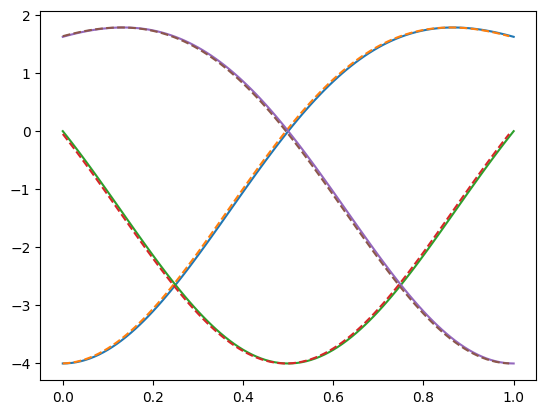

In [13]:
for i in range(Phi.shape[0]):
    plt.plot(x.cpu(), ddPhi[i,:].cpu())
    plt.plot(x[:-1].cpu(), ddPhi_fd[i,:].cpu(), '--')
    

In [14]:
torch.cuda.empty_cache()
N_samples = 1
lambdas=(0.5,0.5)
b_min = -1
b_max = 1
b = torch.rand(N_samples)*(b_max - b_min) + b_min
c_min = 0
c_max = 1
c = torch.rand(N_samples)*(c_max - c_min) + c_min
grf = GRF(N_samples=N_samples, lambdas=lambdas, b=b, c=c, device='cuda', dtype=torch.float64, n=None)

In [15]:
basis_x = GaussianRBFBasis(lambdas=grf.lambdas[0], mus=grf.mus[0])
basis_y = GaussianRBFBasis(lambdas=grf.lambdas[1], mus=grf.mus[1])

basis = TensorProductBasis((basis_x, basis_y))

In [16]:
grid = torch.meshgrid(x.cpu(), y.cpu(), indexing='xy')

In [17]:
f = basis.forward(grf.f_m, X)[0]

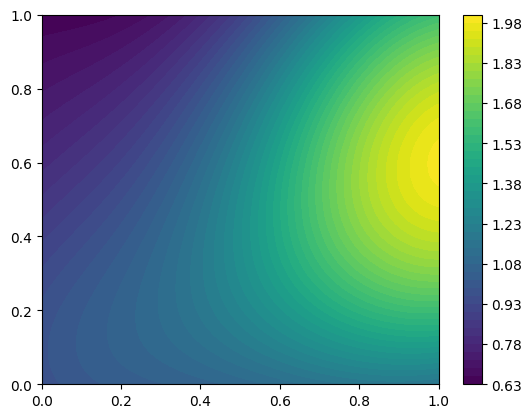

In [18]:
plt.contourf(grid[1], grid[0], f.cpu()[:,:], levels=50)
plt.colorbar()

In [19]:
grad = basis.grad(grf.f_m, X)[0]

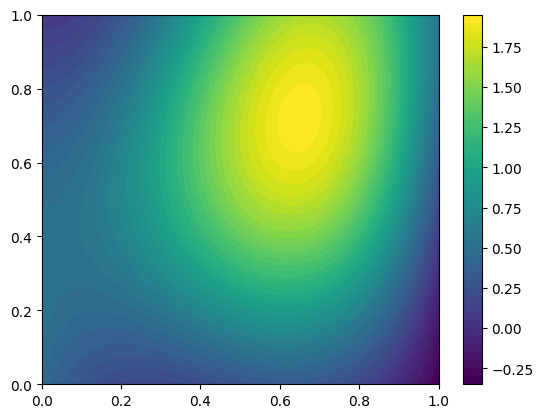

In [20]:
plt.contourf(grid[1], grid[0], grad.cpu()[:,:,0], levels=50, vmin=grad.cpu()[:,:,0].min(), vmax=grad.cpu()[:,:,0].max())
plt.colorbar()

In [21]:
grad_fd = torch.zeros_like(grad)

In [22]:
grad_fd.shape

torch.Size([101, 101, 2])

In [23]:
grad_fd[:-1,:,0] = torch.diff(f, dim=0) / dx

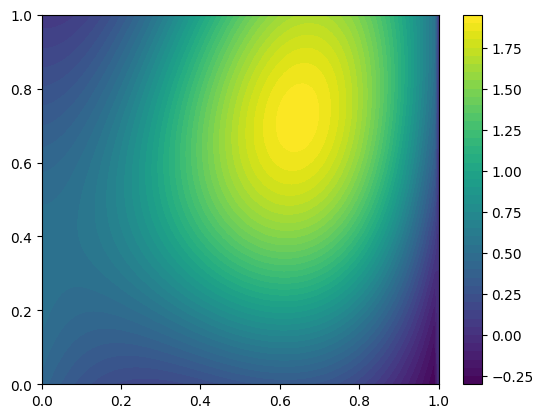

In [24]:
plt.contourf(grid[1], grid[0], grad_fd.cpu()[:,:,0], levels=50, vmin=grad.cpu()[:,:,0].min(), vmax=grad.cpu()[:,:,0].max())
plt.colorbar()

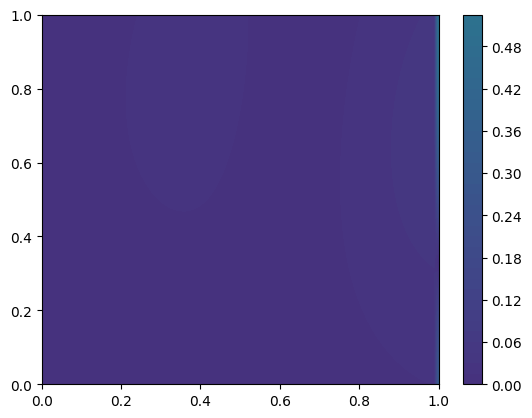

In [25]:
plt.contourf(grid[1], grid[0], torch.abs(grad - grad_fd).cpu()[:,:,0], levels=50, vmin=grad.cpu()[:,:,0].min(), vmax=grad.cpu()[:,:,0].max())
plt.colorbar()

In [26]:
laplacian = basis.laplacian(grf.f_m, X)[0]

In [37]:
laplacian_fd = torch.zeros_like(laplacian)
laplacian_fd[:-1,:,0] = torch.diff(grad[:,:,0], dim=0) / dx

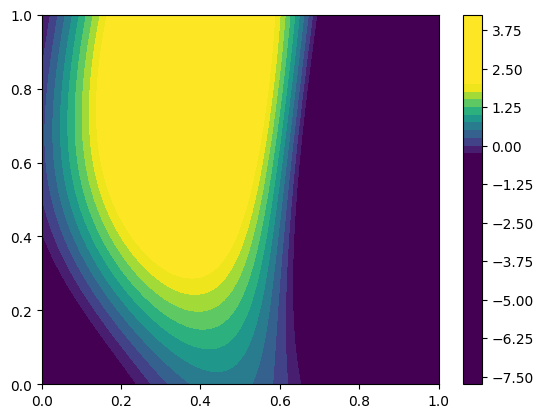

In [38]:
plt.contourf(grid[1], grid[0], laplacian.cpu()[:,:,0], levels=50, vmin=grad.cpu()[:,:,0].min(), vmax=grad.cpu()[:,:,0].max())
plt.colorbar()

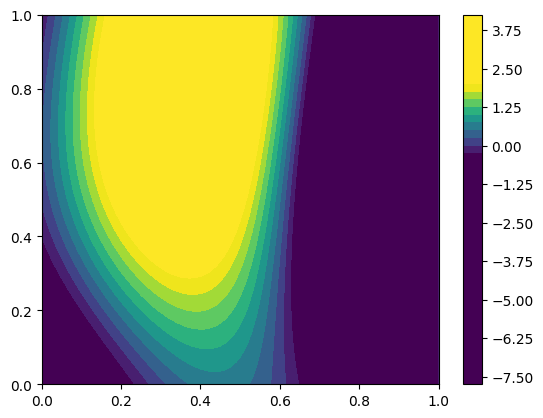

In [39]:
plt.contourf(grid[1], grid[0], laplacian_fd.cpu()[:,:,0], levels=50, vmin=grad.cpu()[:,:,0].min(), vmax=grad.cpu()[:,:,0].max())
plt.colorbar()